# Lab 01 – Sentiment Analysis Using Traditional Machine Learning

Module: PUSL 3205 – Large Language Models and Generative AI

## Objective

To practice basic Natural Language Processing techniques,
including text preprocessing, exploratory data analysis,
Bag of Words, TF-IDF, machine learning classification
and model performance evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import csv

from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Locate the Lab 01 project directory

current_dir = Path.cwd()

possible_paths = [
    current_dir,
    current_dir.parent,
    current_dir / "Lab-01-Machine-Learning"
]

project_dir = next(
    (p for p in possible_paths if (p / "data").exists()),
    None
)

if project_dir is None:
    raise FileNotFoundError("Lab 01 data folder not found")

data_dir = project_dir / "data"
results_dir = project_dir / "results"

results_dir.mkdir(exist_ok=True)

# Dataset filenames
files = [
    "amazon_cells_labelled.txt",
    "imdb_labelled.txt",
    "yelp_labelled.txt"
]

dataframes = []

# Load each dataset
for file in files:

    df_part = pd.read_csv(
        data_dir / file,
        sep="\t",
        header=None,
        names=["sentence", "label"],
        quoting=csv.QUOTE_NONE
    )

    df_part["source"] = file.replace("_labelled.txt", "")

    dataframes.append(df_part)

# Combine the three datasets
df = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head(10)

Dataset loaded successfully!
Dataset shape: (3000, 3)


,sentence,label,source
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells
5,I have to jiggle the plug to get it to line up...,0,amazon_cells
6,If you have several dozen or several hundred c...,0,amazon_cells
7,If you are Razr owner...you must have this!,1,amazon_cells
8,"Needless to say, I wasted my money.",0,amazon_cells
9,What a waste of money and time!.,0,amazon_cells


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nSentiment distribution:")
print(df["label"].value_counts())

print("\nDataset sources:")
print(df["source"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   sentence  3000 non-null   str  
 1   label     3000 non-null   int64
 2   source    3000 non-null   str  
dtypes: int64(1), str(2)
memory usage: 70.4 KB

Missing values:
sentence    0
label       0
source      0
dtype: int64

Duplicate records:
17

Sentiment distribution:
label
0    1500
1    1500
Name: count, dtype: int64

Dataset sources:
source
amazon_cells    1000
imdb            1000
yelp            1000
Name: count, dtype: int64


In [4]:
df = df.dropna(subset=["sentence", "label"])

df["label"] = df["label"].astype(int)

df = df[df["label"].isin([0, 1])]

df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)

Dataset shape: (3000, 3)


In [5]:
def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Normalize and remove apostrophes
    text = text.replace("’", "'")
    text = text.replace("'", "")

    # Remove punctuation and unnecessary characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Create a clean-text column
df["clean_text"] = df["sentence"].apply(preprocess_text)

# Compare original and cleaned sentences
df[["sentence", "clean_text", "label"]].head(10)


,sentence,clean_text,label
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",good case excellent value,1
2,Great for the jawbone.,great for the jawbone,1
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...,0
4,The mic is great.,the mic is great,1
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...,0
7,If you are Razr owner...you must have this!,if you are razr owner you must have this,1
8,"Needless to say, I wasted my money.",needless to say i wasted my money,0
9,What a waste of money and time!.,what a waste of money and time,0


In [6]:
df = df[df["clean_text"].str.strip() != ""].copy()

print("Repeated cleaned sentences:",
      df["clean_text"].duplicated().sum())

# Remove repeated cleaned sentences before splitting
# to reduce train-test data leakage
df_model = df.drop_duplicates(
    subset="clean_text",
    keep=False
).reset_index(drop=True)

print("Original cleaned dataset:", df.shape)
print("Dataset for modelling:", df_model.shape)

Repeated cleaned sentences: 31
Original cleaned dataset: (3000, 4)
Dataset for modelling: (2946, 4)


In [7]:
print("POSITIVE REVIEWS")
print("-" * 50)

for sentence in df[df["label"] == 1]["sentence"].head(5):
    print(sentence)

print("\nNEGATIVE REVIEWS")
print("-" * 50)

for sentence in df[df["label"] == 0]["sentence"].head(5):
    print(sentence)

POSITIVE REVIEWS
--------------------------------------------------
Good case, Excellent value.
Great for the jawbone.
The mic is great.
If you are Razr owner...you must have this!
And the sound quality is great.

NEGATIVE REVIEWS
--------------------------------------------------
So there is no way for me to plug it in here in the US unless I go by a converter.
Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
I have to jiggle the plug to get it to line up right to get decent volume.
If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
Needless to say, I wasted my money.


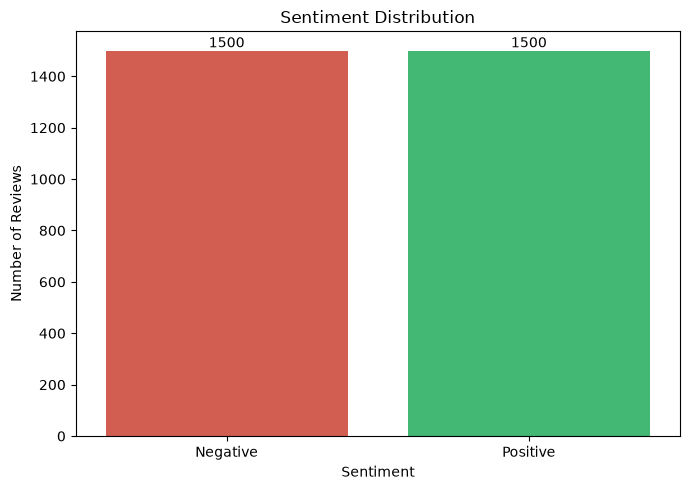

In [8]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette=["#E74C3C", "#2ECC71"],
    legend=False
)

ax.set_xticks([0, 1], ["Negative", "Positive"])

for container in ax.containers:
    ax.bar_label(container)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    results_dir / "sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

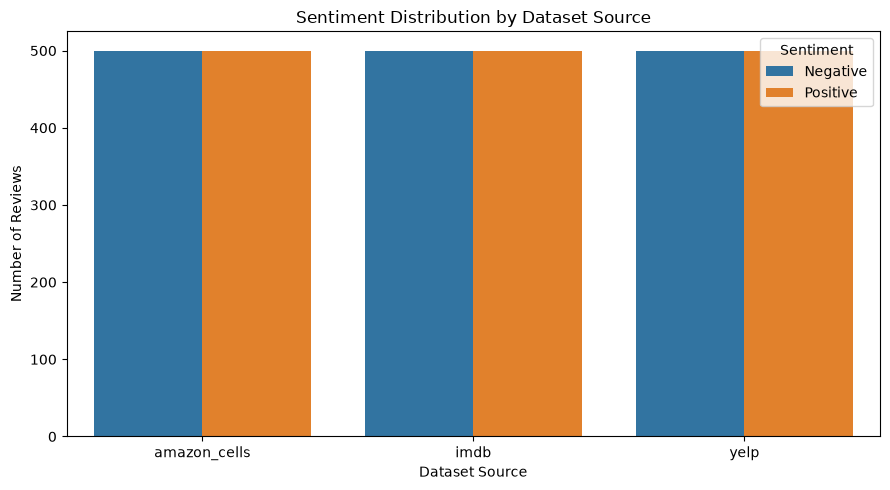

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="source",
    hue="label"
)

plt.title("Sentiment Distribution by Dataset Source")
plt.xlabel("Dataset Source")
plt.ylabel("Number of Reviews")

plt.legend(
    title="Sentiment",
    labels=["Negative", "Positive"]
)

plt.tight_layout()

plt.savefig(
    results_dir / "source_distribution.png",
    dpi=300
)

plt.show()

In [10]:
all_words = " ".join(df["clean_text"]).split()

word_counts = Counter(all_words)

common_words = word_counts.most_common(20)

word_df = pd.DataFrame(
    common_words,
    columns=["word", "frequency"]
)

word_df

,word,frequency
0,the,1953
1,and,1138
2,i,897
3,a,889
4,is,754
5,it,674
6,to,670
7,this,643
8,of,624
9,was,571


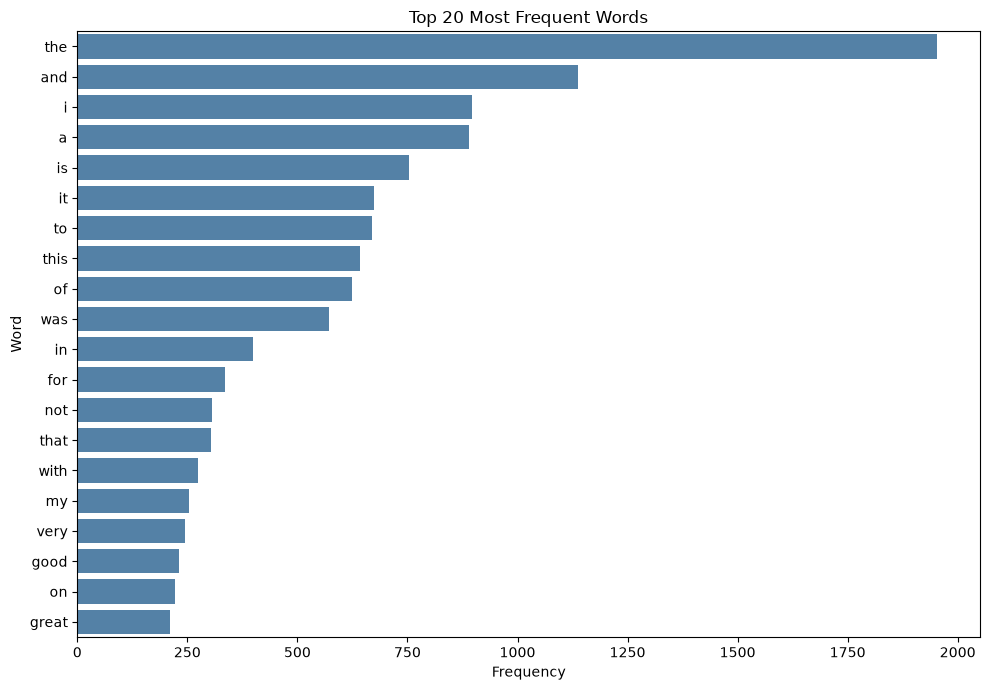

In [11]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=word_df,
    x="frequency",
    y="word",
    color="steelblue"
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()

plt.savefig(
    results_dir / "frequent_words.png",
    dpi=300
)

plt.show()

In [12]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Exclude common English words for visualization only
stop_words = set(ENGLISH_STOP_WORDS)

# Preserve sentiment-related negation words
stop_words -= {"no", "not", "never", "nor", "nothing"}

positive_words = " ".join(
    df[df["label"] == 1]["clean_text"]
).split()

negative_words = " ".join(
    df[df["label"] == 0]["clean_text"]
).split()

positive_words = [
    word for word in positive_words
    if word not in stop_words
]

negative_words = [
    word for word in negative_words
    if word not in stop_words
]

positive_counts = Counter(positive_words).most_common(15)
negative_counts = Counter(negative_words).most_common(15)

positive_df = pd.DataFrame(
    positive_counts,
    columns=["word", "frequency"]
)

negative_df = pd.DataFrame(
    negative_counts,
    columns=["word", "frequency"]
)

print("Frequent positive words:")
display(positive_df)

print("Frequent negative words:")
display(negative_df)

Frequent positive words:


,word,frequency
0,great,201
1,good,177
2,film,103
3,phone,87
4,movie,85
5,best,63
6,food,60
7,place,58
8,like,56
9,not,56


Frequent negative words:


,word,frequency
0,not,250
1,bad,100
2,movie,96
3,phone,78
4,dont,70
5,like,69
6,just,66
7,food,66
8,time,62
9,no,61


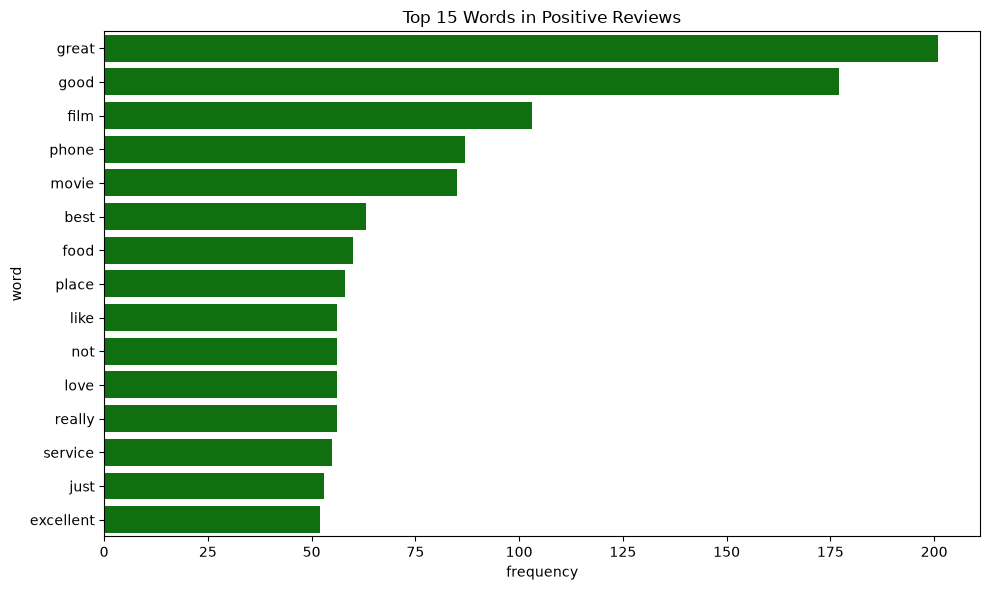

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=positive_df,
    x="frequency",
    y="word",
    color="green"
)

plt.title("Top 15 Words in Positive Reviews")

plt.tight_layout()

plt.savefig(
    results_dir / "positive_words.png",
    dpi=300
)

plt.show()

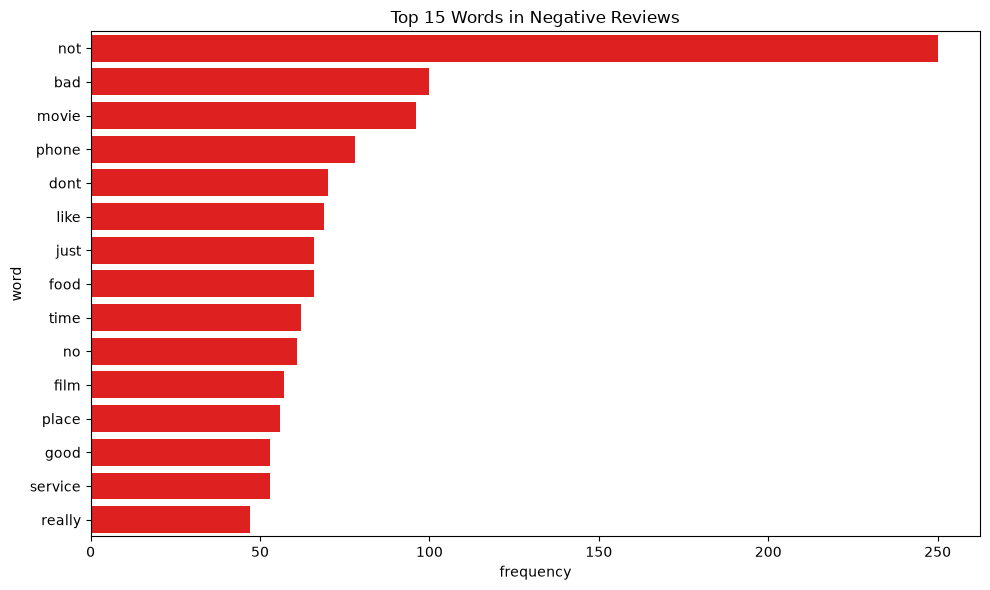

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=negative_df,
    x="frequency",
    y="word",
    color="red"
)

plt.title("Top 15 Words in Negative Reviews")

plt.tight_layout()

plt.savefig(
    results_dir / "negative_words.png",
    dpi=300
)

plt.show()

Average review length by sentiment:
label
0    11.946667
1    11.840667
Name: word_count, dtype: float64


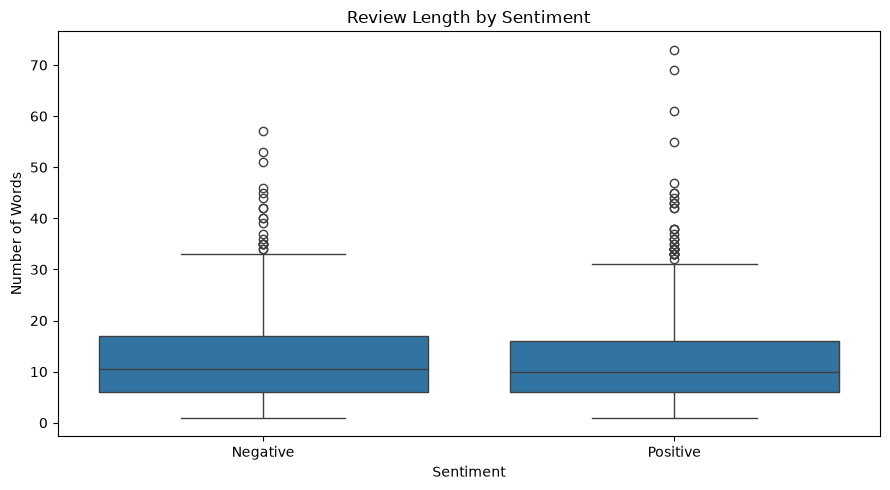

In [15]:
df["word_count"] = df["clean_text"].apply(
    lambda text: len(text.split())
)

print("Average review length by sentiment:")

print(
    df.groupby("label")["word_count"].mean()
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="label",
    y="word_count"
)

plt.xticks([0, 1], ["Negative", "Positive"])

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.tight_layout()

plt.savefig(
    results_dir / "review_length.png",
    dpi=300
)

plt.show()

In [16]:
X = df_model["clean_text"]
y = df_model["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Total samples: 2946
Training samples: 2356
Testing samples: 590

Training class distribution:
label
1    1180
0    1176
Name: count, dtype: int64

Testing class distribution:
label
1    296
0    294
Name: count, dtype: int64


In [17]:
bow_vectorizer = CountVectorizer()

# Learn vocabulary only from training data
X_train_bow = bow_vectorizer.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_bow = bow_vectorizer.transform(X_test)

print("Training BOW shape:", X_train_bow.shape)
print("Testing BOW shape:", X_test_bow.shape)

print(
    "Vocabulary size:",
    len(bow_vectorizer.vocabulary_)
)

print("\nSample vocabulary:")

print(
    bow_vectorizer.get_feature_names_out()[:30]
)

Training BOW shape: (2356, 4554)
Testing BOW shape: (590, 4554)
Vocabulary size: 4554

Sample vocabulary:
['10' '100' '11' '12' '13' '15' '15g' '15pm' '17' '18' '1928' '1947'
 '1948' '1949' '1971' '1979' '1980s' '1986' '1998' '20' '2000' '2005'
 '2006' '2007' '20th' '2160' '23' '24' '25' '2mp']


In [18]:
bow_sample = pd.DataFrame(
    X_train_bow[:5, :15].toarray(),
    columns=bow_vectorizer.get_feature_names_out()[:15]
)

bow_sample

,10,100,11,12,13,15,15g,15pm,17,18,1928,1947,1948,1949,1971
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [19]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_bow, y_train)

lr_predictions = lr_model.predict(X_test_bow)

print("Logistic Regression training completed!")

print("\nSample predictions:")
print(lr_predictions[:10])

Logistic Regression training completed!

Sample predictions:
[1 1 1 0 1 1 0 1 1 0]


In [20]:
svm_model = LinearSVC(
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_train_bow, y_train)

svm_predictions = svm_model.predict(X_test_bow)

print("SVM training completed!")

print("\nSample predictions:")
print(svm_predictions[:10])

SVM training completed!

Sample predictions:
[1 1 1 0 0 1 0 1 1 0]


In [21]:
def evaluate_model(model_name, y_true, y_pred):

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

    return results

In [22]:
model_results = []

model_results.append(
    evaluate_model(
        "BoW + Logistic Regression",
        y_test,
        lr_predictions
    )
)

model_results.append(
    evaluate_model(
        "BoW + SVM",
        y_test,
        svm_predictions
    )
)

results_df = pd.DataFrame(model_results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,BoW + Logistic Regression,0.8153,0.8127,0.8209,0.8168
1,BoW + SVM,0.7814,0.7668,0.8108,0.7882


In [23]:
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        lr_predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

print("SVM CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        svm_predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.82      0.81      0.81       294
    Positive       0.81      0.82      0.82       296

    accuracy                           0.82       590
   macro avg       0.82      0.82      0.82       590
weighted avg       0.82      0.82      0.82       590

SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.80      0.75      0.77       294
    Positive       0.77      0.81      0.79       296

    accuracy                           0.78       590
   macro avg       0.78      0.78      0.78       590
weighted avg       0.78      0.78      0.78       590



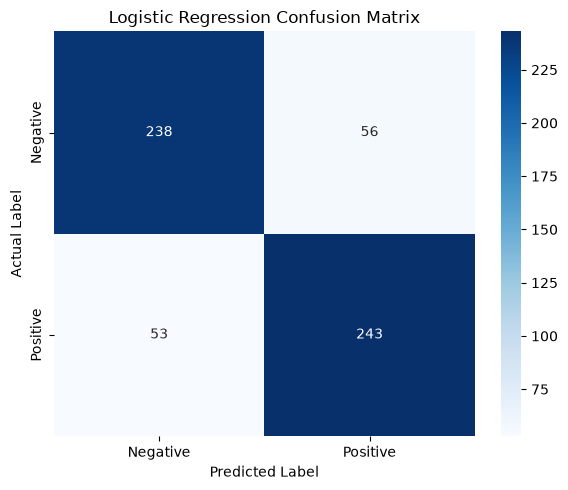

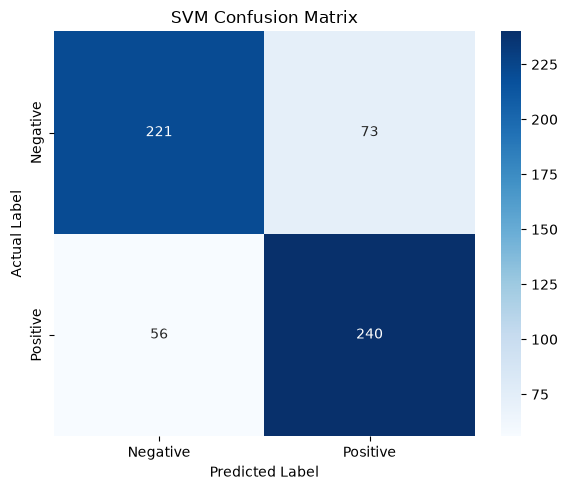

In [24]:
def plot_confusion_matrix(y_true, y_pred, title, filename):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()

    plt.savefig(
        results_dir / filename,
        dpi=300
    )

    plt.show()


plot_confusion_matrix(
    y_test,
    lr_predictions,
    "Logistic Regression Confusion Matrix",
    "lr_confusion_matrix.png"
)

plot_confusion_matrix(
    y_test,
    svm_predictions,
    "SVM Confusion Matrix",
    "svm_confusion_matrix.png"
)

In [25]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)

TF-IDF training shape: (2356, 4554)
TF-IDF testing shape: (590, 4554)


In [26]:
lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tfidf.fit(X_train_tfidf, y_train)

lr_tfidf_predictions = lr_tfidf.predict(X_test_tfidf)

print("TF-IDF Logistic Regression trained!")

TF-IDF Logistic Regression trained!


In [27]:
svm_tfidf = LinearSVC(
    random_state=42,
    max_iter=5000
)

svm_tfidf.fit(X_train_tfidf, y_train)

svm_tfidf_predictions = svm_tfidf.predict(X_test_tfidf)

print("TF-IDF SVM trained!")

TF-IDF SVM trained!


In [28]:
all_results = [
    evaluate_model(
        "BoW + Logistic Regression",
        y_test,
        lr_predictions
    ),

    evaluate_model(
        "BoW + SVM",
        y_test,
        svm_predictions
    ),

    evaluate_model(
        "TF-IDF + Logistic Regression",
        y_test,
        lr_tfidf_predictions
    ),

    evaluate_model(
        "TF-IDF + SVM",
        y_test,
        svm_tfidf_predictions
    )
]

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

results_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("Highest test F1-score:")
print(results_df.iloc[0])

,Model,Accuracy,Precision,Recall,F1-Score
0,BoW + Logistic Regression,0.8153,0.8127,0.8209,0.8168
1,TF-IDF + SVM,0.8068,0.7898,0.8378,0.8131
2,TF-IDF + Logistic Regression,0.8051,0.8007,0.8142,0.8074
3,BoW + SVM,0.7814,0.7668,0.8108,0.7882


Highest test F1-score:
Model        BoW + Logistic Regression
Accuracy                      0.815254
Precision                     0.812709
Recall                        0.820946
F1-Score                      0.816807
Name: 0, dtype: object


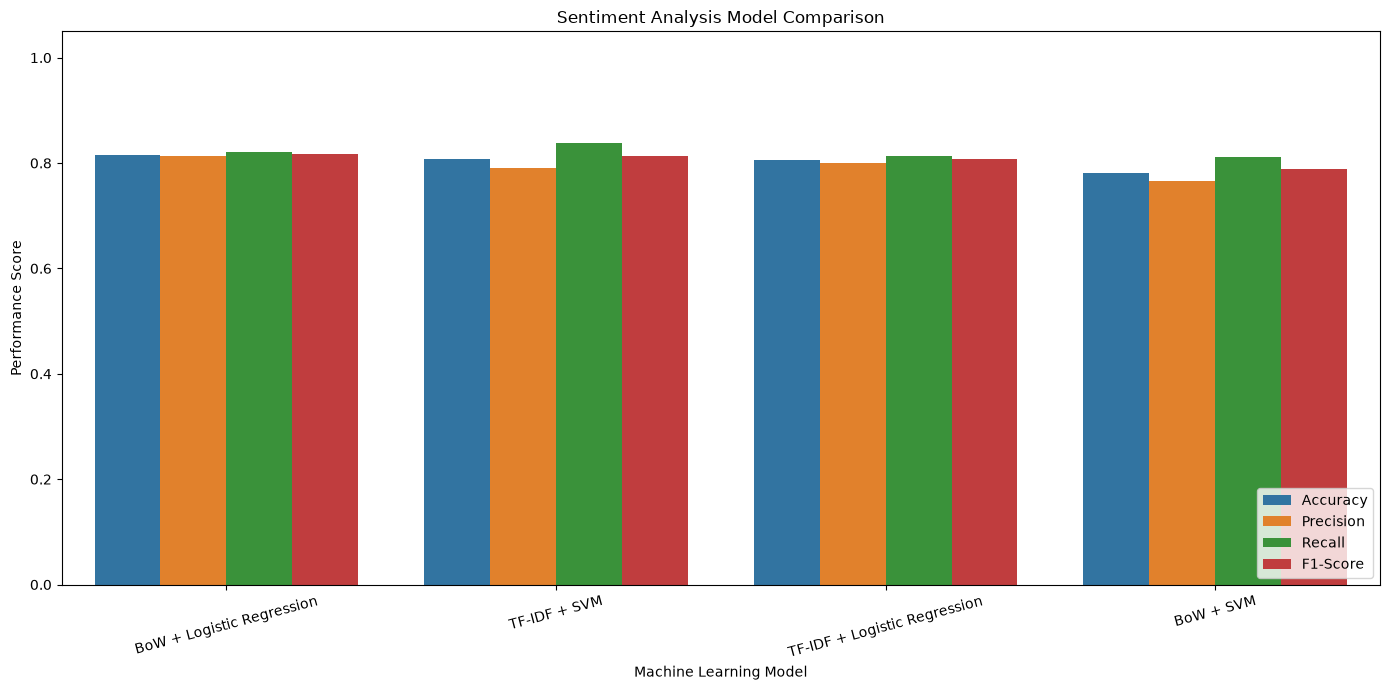

In [29]:
comparison_df = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Sentiment Analysis Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)
plt.xticks(rotation=15)

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    results_dir / "model_comparison.png",
    dpi=300
)

plt.show()

In [30]:
def predict_sentiment(sentence):

    cleaned_sentence = preprocess_text(sentence)

    vectorized_sentence = tfidf_vectorizer.transform(
        [cleaned_sentence]
    )

    prediction = svm_tfidf.predict(
        vectorized_sentence
    )[0]

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

In [31]:
test_sentences = [
    "This product is absolutely amazing!",
    "I really love this movie.",
    "The food was delicious and the service was excellent.",
    "This is the worst product I have ever purchased.",
    "I am very disappointed with the service.",
    "The movie was boring and terrible.",
    "The phone is good but the battery is terrible.",
    "I do not recommend this restaurant.",
    "The movie was not bad at all.",
    "The delivery arrived yesterday."
]

prediction_results = []

for sentence in test_sentences:

    sentiment = predict_sentiment(sentence)

    prediction_results.append({
        "Sentence": sentence,
        "Predicted Sentiment": sentiment
    })

predictions_df = pd.DataFrame(prediction_results)

display(predictions_df)

predictions_df.to_csv(
    results_dir / "new_sentence_predictions.csv",
    index=False
)

,Sentence,Predicted Sentiment
0,This product is absolutely amazing!,Positive
1,I really love this movie.,Positive
2,The food was delicious and the service was exc...,Positive
3,This is the worst product I have ever purchased.,Negative
4,I am very disappointed with the service.,Negative
5,The movie was boring and terrible.,Negative
6,The phone is good but the battery is terrible.,Negative
7,I do not recommend this restaurant.,Negative
8,The movie was not bad at all.,Negative
9,The delivery arrived yesterday.,Positive


In [33]:
user_sentence = input("Enter a sentence: ")

if user_sentence.strip():

    prediction = predict_sentiment(user_sentence)

    print("\nOriginal Sentence:", user_sentence)
    print("Cleaned Sentence:", preprocess_text(user_sentence))
    print("Predicted Sentiment:", prediction)

else:
    print("Please enter a valid sentence.")


Original Sentence: the best movie ever seen
Cleaned Sentence: the best movie ever seen
Predicted Sentiment: Positive


In [34]:
error_df = pd.DataFrame({
    "Sentence": X_test.to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": svm_tfidf_predictions
})

incorrect_predictions = error_df[
    error_df["Actual"] != error_df["Predicted"]
].copy()

print(
    "Number of incorrect predictions:",
    len(incorrect_predictions)
)

display(incorrect_predictions.head(15))

incorrect_predictions.to_csv(
    results_dir / "incorrect_predictions.csv",
    index=False
)

Number of incorrect predictions: 114


,Sentence,Actual,Predicted
4,ordered burger rare came in well done,0,1
6,i cant wait to go back,1,0
7,we received a white colored battery that goes ...,0,1
12,the movie is not completely perfect but titta ...,1,0
13,i had to purchase a different case,0,1
17,it has everything you could want suspense dram...,1,0
19,the owner used to work at nobu so this place i...,1,0
21,it really created a unique feeling though,1,0
26,very displeased,0,1
28,this was my first time and i cant wait until t...,1,0


In [ ]:
import joblib

joblib.dump(
    svm_tfidf,
    results_dir / "sentiment_model.pkl"
)

joblib.dump(
    tfidf_vectorizer,
    results_dir / "tfidf_vectorizer.pkl"
)

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


: 